In [1]:
from sklearn.datasets import make_regression

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

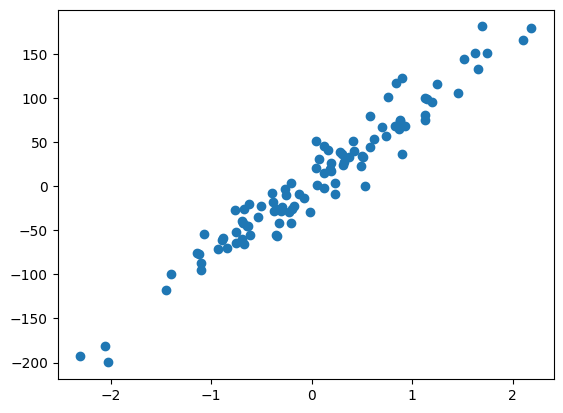

In [3]:
x,y = make_regression(
    n_samples = 100,
    n_features = 1,
    n_informative = 1,
    n_targets = 1,
    noise = 20,
    random_state = 1)

plt.scatter(x, y)

In [4]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

lr_model.fit(x, y)

m = lr_model.coef_[0]
c = lr_model.intercept_ 
print(f"Slope(m): {m}")
print(f"Intercept(c): {c}")

Slope(m): 82.48449929280291
Intercept(c): 4.054028777621713


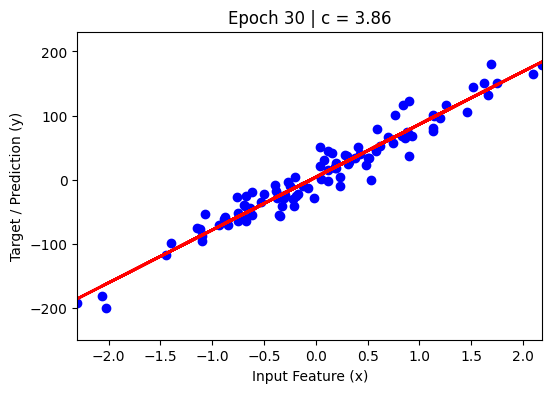

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# -----------------------------
# Prepare data (IMPORTANT FIX)
# -----------------------------
x_flat = x.ravel()   # ✅ convert to 1D
y_flat = y.ravel()   # ✅ convert to 1D

# -----------------------------
# Gradient Descent
# -----------------------------
c = -150
lr = 0.001
epochs = 30

all_c = []
all_cost = []

for i in range(epochs):
    slope = 0
    cost = 0
    
    for j in range(len(x_flat)):
        slope = slope - 2*(y_flat[j] - (m * x_flat[j]) - c)
        cost = cost + (y_flat[j] - m * x_flat[j] - c) ** 2

    c = c - (lr * slope)

    all_c.append(c)        # now scalar ✅
    all_cost.append(cost)

# -----------------------------
# Animation: Line fitting
# -----------------------------
fig, ax = plt.subplots(figsize=(6,4))

# scatter data
ax.scatter(x_flat, y_flat, color='blue')

# labels
ax.set_xlabel("Input Feature (x)")
ax.set_ylabel("Target / Prediction (y)")

# limits
ax.set_xlim(x_flat.min(), x_flat.max())
ax.set_ylim(y_flat.min()-50, y_flat.max()+50)

# line
line, = ax.plot([], [], 'r-', linewidth=2)

def animate(i):
    c_val = all_c[i]   # already scalar now ✅
    
    y_pred = m * x_flat + c_val
    
    line.set_data(x_flat, y_pred)
    
    ax.set_title(f"Epoch {i+1} | c = {round(c_val,2)}")
    
    return line,

# animation
anim = animation.FuncAnimation(
    fig, animate, frames=len(all_c), interval=500, repeat=False
)

# save GIF
anim.save("Viz_5.gif", writer=animation.PillowWriter(fps=2))

# display (optional)
display(HTML(anim.to_jshtml()))

plt.show()

In [9]:
all_c = np.array(all_c).ravel()

all_c

array([-119.18919424,  -94.54054964,  -74.82163396,  -59.04650141,
        -46.42639537,  -36.33031054,  -28.25344268,  -21.79194839,
        -16.62275295,  -12.48739661,   -9.17911153,   -6.53248347,
         -4.41518102,   -2.72133906,   -1.36626549,   -0.28220664,
          0.58504044,    1.27883811,    1.83387624,    2.27790675,
          2.63313116,    2.91731068,    3.1446543 ,    3.3265292 ,
          3.47202911,    3.58842905,    3.68154899,    3.75604495,
          3.81564171,    3.86331913])

In [10]:
all_cost = np.array(all_cost).ravel()
all_cost

array([2406521.13472932, 1552145.95855513, 1005345.84580366,
        655393.77364271,  431424.4474597 ,  288084.07870258,
        196346.24269802,  137634.0276551 ,  100058.21002763,
         76009.68674606,   60618.63184584,   50768.35670971,
         44464.18062258,   40429.50792682,   37847.31740154,
         36194.71546535,   35137.05022619,   34460.14447313,
         34026.92479117,   33749.66419472,   33572.21741299,
         33458.65147268,   33385.96927089,   33339.45266174,
         33309.68203188,   33290.62882877,   33278.43477878,
         33270.63058679,   33265.63590392,   33262.43930688])

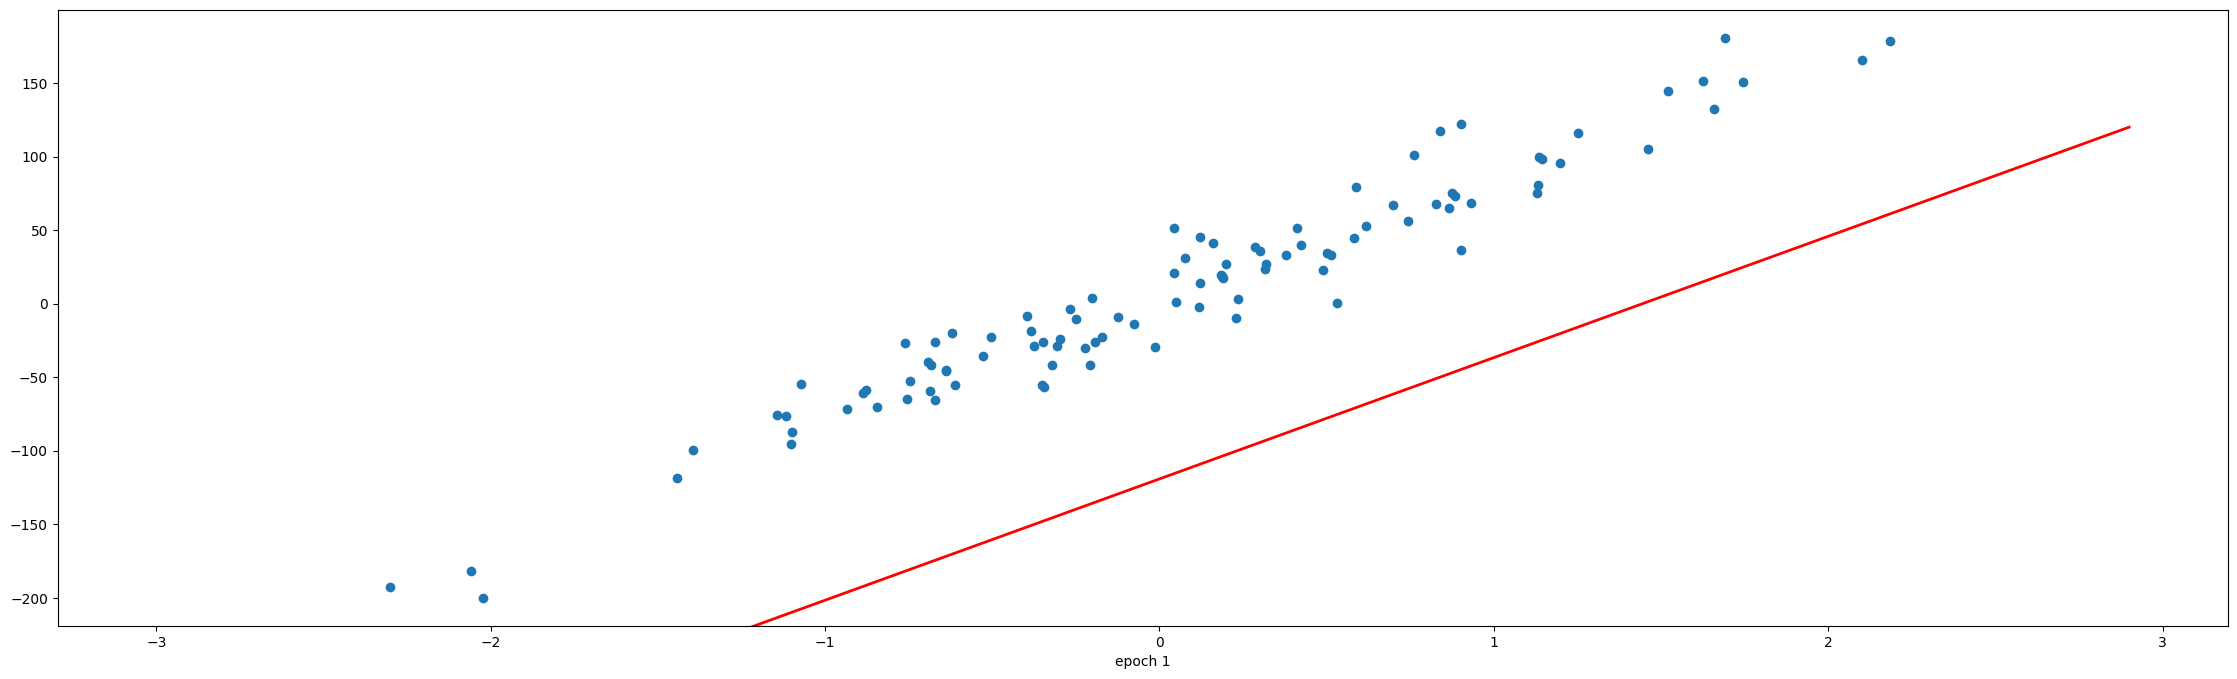

In [11]:
fig, ax = plt.subplots(figsize=(28, 8))
#fig.set_tight_layout(True)

x_i = np.arange(-3, 3, 0.1)
y_i = x_i*m -150
ax.scatter(x, y)
line, = ax.plot(x_i, x_i*50 - 4, 'r-', linewidth=2)

def update(i):
    label = 'epoch {0}'.format(i + 1)
    line.set_ydata(x_i*m + all_c[i])
    ax.set_xlabel(label)
    # return line, ax

anim = FuncAnimation(fig, update, repeat=True, frames=epochs, interval=500)

#f = r"animation.gif" 
#writergif = animation.PillowWriter(fps=2) 
#anim.save(f, writer=writergif)

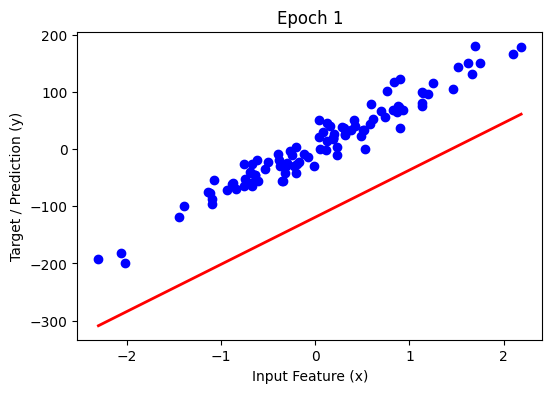

In [12]:
from IPython.display import HTML
import matplotlib.animation as animation

fig1, ax1 = plt.subplots(figsize=(6, 4))

ax1.scatter(x, y, color='blue')

# ✅ Axis labels
ax1.set_xlabel("Input Feature (x)")
ax1.set_ylabel("Target / Prediction (y)")

x_line = np.linspace(x.min(), x.max(), 100)
line, = ax1.plot(x_line, m * x_line + all_c[0], 'r-', linewidth=2)

def update_line(i):
    line.set_ydata(m * x_line + all_c[i])
    ax1.set_title(f"Epoch {i+1}")
    return line,

anim1 = FuncAnimation(fig1, update_line, frames=epochs, interval=500)

# ✅ Save GIF
anim1.save("Viz_1.gif", writer=animation.PillowWriter(fps=2))

# ✅ Display
display(HTML(anim1.to_jshtml()))

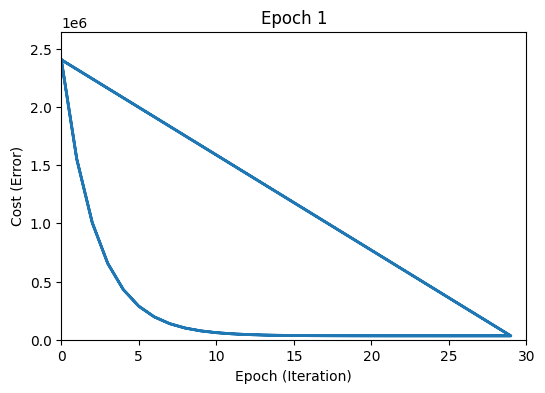

In [13]:
from IPython.display import HTML
import matplotlib.animation as animation

# -----------------------------
# ANIMATION 2: Cost vs Epoch
# -----------------------------
fig2, ax2 = plt.subplots(figsize=(6, 4))

ax2.set_xlim(0, epochs)
ax2.set_ylim(0, max(all_cost) * 1.1)

# ✅ Axis labels
ax2.set_xlabel("Epoch (Iteration)")
ax2.set_ylabel("Cost (Error)")

line2, = ax2.plot([], [], lw=2)

xdata, ydata = [], []

def animate_cost(i):
    xdata.append(i)
    ydata.append(all_cost[i])

    line2.set_data(xdata, ydata)
    ax2.set_title(f"Epoch {i+1}")

    return line2,

anim2 = animation.FuncAnimation(
    fig2, animate_cost, frames=epochs, interval=500
)

# ✅ Save GIF
anim2.save("Viz_2.gif", writer=animation.PillowWriter(fps=2))

# ✅ Display in Jupyter
display(HTML(anim2.to_jshtml()))

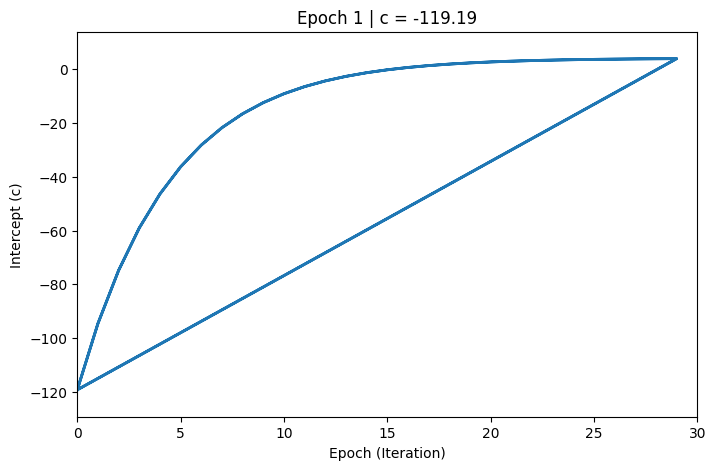

In [14]:
from IPython.display import HTML
import matplotlib.animation as animation

fig = plt.figure(figsize=(8,5)) 
axis = plt.axes()

axis.set_xlim(0, len(all_c))
axis.set_ylim(min(all_c)-10, max(all_c)+10)

# ✅ Axis labels
axis.set_xlabel("Epoch (Iteration)")
axis.set_ylabel("Intercept (c)")

line, = axis.plot([], [], lw=2) 
  
xdata, ydata = [], [] 
  
def animate(i): 
    xdata.append(i)
    ydata.append(all_c[i])
    
    line.set_data(xdata, ydata) 
    
    # ✅ Dynamic title with value (upgrade)
    axis.set_title(f"Epoch {i+1} | c = {round(all_c[i], 2)}")
      
    return line, 
  
anim = animation.FuncAnimation(
    fig, animate, frames=len(all_c), repeat=False, interval=500
)

# ✅ Save GIF
anim.save("Viz_3.gif", writer=animation.PillowWriter(fps=2))

# ✅ Display in Jupyter
display(HTML(anim.to_jshtml()))

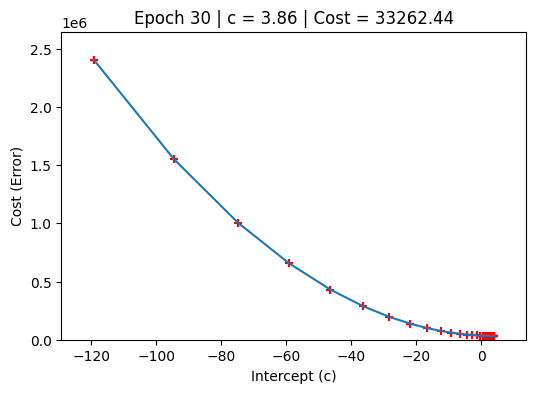

In [15]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(6,4))

# Plot full cost curve
ax.plot(all_c, all_cost)

# ✅ Axis labels
ax.set_xlabel("Intercept (c)")
ax.set_ylabel("Cost (Error)")

# Better dynamic limits
ax.set_xlim(min(all_c)-10, max(all_c)+10)
ax.set_ylim(0, max(all_cost)*1.1)

# Scatter for moving point
x_path, y_path = [], []
sc = ax.scatter([], [], color='red', marker='+')

def animate(i):
    x_path.append(all_c[i])
    y_path.append(all_cost[i])
    
    sc.set_offsets(np.c_[x_path, y_path])
    
    # ✅ Dynamic title with value
    ax.set_title(f"Epoch {i+1} | c = {round(all_c[i],2)} | Cost = {round(all_cost[i],2)}")
    
    return sc,

# Animation
ani = animation.FuncAnimation(
    fig, animate, frames=len(all_c), interval=500, repeat=True
)

# ✅ Save GIF
ani.save("Viz_4.gif", writer=animation.PillowWriter(fps=2))

# (Optional) display in Jupyter
display(HTML(ani.to_jshtml()))

plt.show()

In [19]:
html_content = """
<!DOCTYPE html>
<html>
<head>
    <title>Gradient Descent Dashboard</title>
</head>
<body>

<h1 style="text-align:center;">Gradient Descent Visualization Dashboard</h1>

<div style="display:grid; grid-template-columns: 1fr 1fr; gap:20px;">

<div>
<h3>Viz_1: Line Fitting</h3>
<img src="Viz_1.gif" width="100%">
</div>

<div>
<h3>Viz_2: Cost vs Epoch</h3>
<img src="Viz_2.gif" width="100%">
</div>

<div>
<h3>Viz_3: c vs Epoch</h3>
<img src="Viz_3.gif" width="100%">
</div>

<div>
<h3>Viz_4: Cost vs c (Path)</h3>
<img src="Viz_4.gif" width="100%">
</div>

<div style="grid-column: span 2; text-align:center;">
<h3>Viz_5: Final Line Animation</h3>
<img src="Viz_5.gif" width="60%">
</div>

</div>

</body>
</html>
"""

# Save file
with open("Viz_Dashboard.html", "w") as f:
    f.write(html_content)

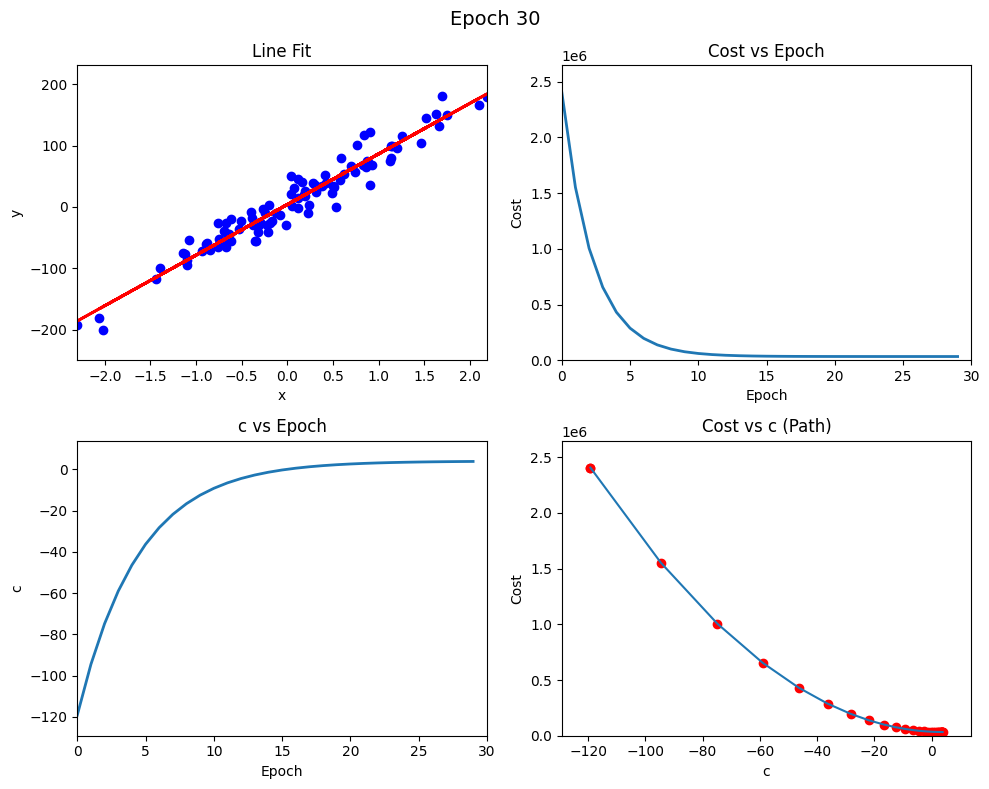

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# -----------------------------
# Prepare data
# -----------------------------
x_flat = x.ravel()
y_flat = y.ravel()

# -----------------------------
# Gradient Descent
# -----------------------------
c = -150
lr = 0.001
epochs = 30

all_c = []
all_cost = []

for i in range(epochs):
    slope = 0
    cost = 0
    
    for j in range(len(x_flat)):
        slope = slope - 2*(y_flat[j] - (m * x_flat[j]) - c)
        cost = cost + (y_flat[j] - m * x_flat[j] - c) ** 2

    c = c - (lr * slope)

    all_c.append(c)
    all_cost.append(cost)

# -----------------------------
# Create Dashboard (2x2)
# -----------------------------
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

# -----------------------------
# 1. Line fitting
# -----------------------------
ax1 = axs[0,0]
ax1.scatter(x_flat, y_flat, color='blue')
line1, = ax1.plot([], [], 'r-', lw=2)
ax1.set_title("Line Fit")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_xlim(x_flat.min(), x_flat.max())
ax1.set_ylim(y_flat.min()-50, y_flat.max()+50)

# -----------------------------
# 2. Cost vs Epoch
# -----------------------------
ax2 = axs[0,1]
line2, = ax2.plot([], [], lw=2)
ax2.set_title("Cost vs Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Cost")
ax2.set_xlim(0, epochs)
ax2.set_ylim(0, max(all_cost)*1.1)

x_cost, y_cost = [], []

# -----------------------------
# 3. c vs Epoch
# -----------------------------
ax3 = axs[1,0]
line3, = ax3.plot([], [], lw=2)
ax3.set_title("c vs Epoch")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("c")
ax3.set_xlim(0, epochs)
ax3.set_ylim(min(all_c)-10, max(all_c)+10)

x_c, y_c = [], []

# -----------------------------
# 4. Cost vs c (path)
# -----------------------------
ax4 = axs[1,1]
ax4.plot(all_c, all_cost)
sc = ax4.scatter([], [], color='red')
ax4.set_title("Cost vs c (Path)")
ax4.set_xlabel("c")
ax4.set_ylabel("Cost")
ax4.set_xlim(min(all_c)-10, max(all_c)+10)
ax4.set_ylim(0, max(all_cost)*1.1)

path_x, path_y = [], []

# -----------------------------
# Animation function
# -----------------------------
def animate(i):
    c_val = all_c[i]

    # 1. Line fit
    y_pred = m * x_flat + c_val
    line1.set_data(x_flat, y_pred)

    # 2. Cost vs epoch
    x_cost.append(i)
    y_cost.append(all_cost[i])
    line2.set_data(x_cost, y_cost)

    # 3. c vs epoch
    x_c.append(i)
    y_c.append(c_val)
    line3.set_data(x_c, y_c)

    # 4. Cost vs c path
    path_x.append(c_val)
    path_y.append(all_cost[i])
    sc.set_offsets(np.c_[path_x, path_y])

    fig.suptitle(f"Epoch {i+1}", fontsize=14)

    return line1, line2, line3, sc

# -----------------------------
# Create animation
# -----------------------------
anim = animation.FuncAnimation(
    fig, animate, frames=epochs, interval=500, repeat=False
)

# -----------------------------
# Save file
# -----------------------------
anim.save("GD_Dashboard.gif", writer=animation.PillowWriter(fps=2))

plt.tight_layout()
plt.show()